In [1]:
! pip install brian2 -q

In [2]:
# Keep numerical outputs and figures inside 01_Original_Colab/results.
from pathlib import Path

ROOT_CANDIDATES = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (p for p in ROOT_CANDIDATES if (p / "01_Original_Colab").is_dir()),
    next((p.parent for p in ROOT_CANDIDATES if p.name == "01_Original_Colab"), Path.cwd()),
)
RESULTS_ROOT = ROOT / "01_Original_Colab" / "results"
CONDITION = "G3.0"
OUTPUT_DIR = RESULTS_ROOT / CONDITION
FIGURES_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.integrate import quad
from scipy.special import erfc
from scipy.optimize import brentq
from scipy.fft import fft
from scipy.ndimage import gaussian_filter1d

import warnings

warnings.filterwarnings('ignore')
prefs.codegen.target = 'cython'

In [4]:
start_scope()
defaultclock.dt = 0.1 * ms           # matches the paper's Euler step (Delta t = 0.1 ms)
seed(4321)                           # global seed: fixes connectivity AND initial voltages

# --- Population sizes -------------------------------------------------------
N_E      = 100000                    # excitatory neurons  -> C_E = 1000
gamma    = 0.25
N_I      = int(gamma * N_E)          # inhibitory neurons  = 2500
N        = N_E + N_I                 # total               = 12500

# --- Sparse connectivity ---------------------------------------------------
epsilon  = 0.01                       # connection probability
C_E      = int(epsilon * N_E)        # exact # excitatory presyn.  = 1000
C_I      = int(epsilon * N_I)        # exact # inhibitory presyn.  = 250

# --- Neuron parameters ------------------------------------------------------
tau     = 20 * ms                    # membrane time constant
theta   = 20 * mV                    # firing threshold
V_r     = 10  * mV                    # reset potential
tau_rp  = 2  * ms                    # absolute refractory period

# --- Synapse parameters -----------------------------------------------------
J   = 1.0 * mV                       # excitatory PSP amplitude
g   = 3.5                            # relative inhibitory strength
D   = 1.5 * ms                       # synaptic transmission delay
RI  = 30 * mV                        # Constant external input

# --- Neuron Group Setup -----------------------------------------------------
neurons = NeuronGroup(
    N,
    model="dv/dt = (-v + RI) / tau : volt (unless refractory)",
    threshold="v > theta",
    reset="v = V_r",
    refractory=tau_rp,
    method="euler",
)
neurons.v = "rand() * mV"            # random initial voltages in [0, 1] mV

exc_neurons = neurons[:N_E]
inh_neurons = neurons[N_E:]


In [5]:
# --- Recurrent synapses (NumPy Fixed In-Degree) -----------------------------
exc_syn = Synapses(exc_neurons, neurons, on_pre="v += J", delay=D)
inh_syn = Synapses(inh_neurons, neurons, on_pre="v += -g*J", delay=D)

# 1. Pre-calculate targets: Every neuron in N gets exactly C_E (or C_I) inputs
targets_E = np.repeat(np.arange(N), C_E)
targets_I = np.repeat(np.arange(N), C_I)

# 2. Pre-calculate sources: Randomly sample from presynaptic pools
# np.random.randint is exceptionally fast and standard for sparse network practice
sources_E = np.random.randint(0, N_E, size=N * C_E)
sources_I = np.random.randint(0, N_I, size=N * C_I)

# 3. Connect synapses directly using the generated NumPy arrays
exc_syn.connect(i=sources_E, j=targets_E)
inh_syn.connect(i=sources_I, j=targets_I)

In [ ]:
# --- Monitors & Execution ---------------------------------------------------
sim_time = 3000 * ms
rate_mon   = PopulationRateMonitor(neurons)
spike_mon  = SpikeMonitor(neurons)

run(sim_time)

In [ ]:
# Extract spike trains from the monitor
spike_trains = spike_mon.spike_trains()
cv_list = []

# Iterate through each neuron's spike train
for neuron_idx, train in spike_trains.items():

    # Ensure there are enough spikes to calculate an ISI
    if len(train) > 2:

        # Calculate Inter-Spike Intervals (ISIs)
        isi = np.diff(train / ms)

        # Calculate CV: Standard Deviation / Mean
        cv = np.std(isi) / np.mean(isi)
        cv_list.append(cv)

# Calculate the network-wide average CV
if cv_list:
    mean_cv = np.mean(cv_list)
    print(f"Average Network CV: {mean_cv:.3f}")
else:
    print("Not enough spikes to calculate CV.")


average_firing_rate = np.mean(rate_mon.rate)
print(f"Average Firing Rate: {average_firing_rate:.2f} Hz")

Average Network CV: 0.070
Average Firing Rate: 85.82 Hz


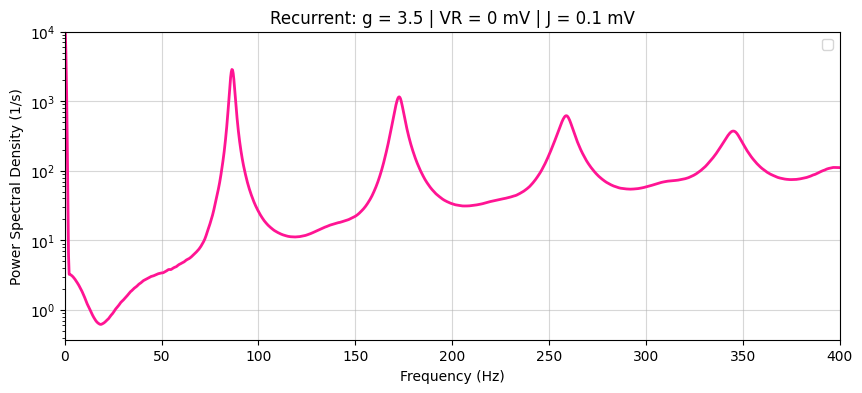

In [ ]:
num_time_bins = int(sim_time/ms)
spk_matrix = np.zeros((N, num_time_bins))

# Extract indices and times directly from the monitor
neuron_indices = spike_mon.i
spike_times = (spike_mon.t / ms).astype(int)

# Populate the matrix efficiently
spk_matrix[neuron_indices, spike_times] = 1

# Compute FFT across the time axis for all neurons at once
y_tilde = fft(spk_matrix, axis=1)

# Calculate power spectrum and average over all neurons
Syy = np.abs(y_tilde)**2 / 2
Savg = np.mean(Syy, axis=0)

# Plotting

f_brian = np.arange(0, len(Savg)) * (1.0 / sim_time)


# --- 2. Smooth the data ---
sigma_val = 1.5
Savg_smooth = gaussian_filter1d(Savg, sigma=sigma_val)


plt.figure(figsize=(10, 4))
plt.semilogy(f_brian, Savg_smooth, color='deeppink', lw =2)
plt.title(f"Recurrent: g = {g} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0, 10000])
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.grid(True, alpha=0.5)
plt.legend()
plt.savefig(FIGURES_DIR / "G3.5_VR0_J0.0.png", dpi=150)
plt.show()

In [ ]:
# Numerical/Iterative Constraints
T_trial = 500.0
dt_sec = 0.0001
N_steps = int(T_trial / dt_sec)
f_cur = np.fft.rfftfreq(N_steps, d=dt_sec)

# Dimensionless equivalents
tau_val = 0.020
vT_val = 0.020
vR_val = 0.0100
tau_ref_val = 0.002
J_val = 0.001
g_val = 3.5
RI_val = 0.030

In [ ]:
def mu_D_stats(nu_in):
    gamma_frac = 0.25
    mu = RI_val + C_E * J_val * tau_val * (1.0 - gamma_frac * g_val) * nu_in
    return mu

def simulate_lif_vectorized(RI_array):
    v = vR_val
    ref_steps = 0
    spike_indices = []

    dt_over_tau = dt_sec / tau_val
    ref_limit = int(tau_ref_val / dt_sec)

    for n in range(N_steps):
        if ref_steps > 0:
            ref_steps -= 1
            v = vR_val
        else:
            v += (-v + RI_array[n]) * dt_over_tau
            if v >= vT_val:
                spike_indices.append(n)
                v = vR_val
                ref_steps = ref_limit

    return np.array(spike_indices) * dt_sec

def generate_colored_noise(S_x_prev, f_prev, nu_in):
    mu = mu_D_stats(nu_in)
    coeff = (C_E * J_val**2 + C_I * (g_val * J_val)**2) * tau_val**2

    f_gen = np.fft.rfftfreq(N_steps, d=dt_sec)
    S_eta = coeff * np.interp(f_gen, f_prev, S_x_prev, left=S_x_prev[0], right=S_x_prev[-1])

    amp = np.sqrt(np.maximum(S_eta, 0) * N_steps / (2.0 * dt_sec))
    phases = np.random.uniform(0, 2.0 * np.pi, len(f_gen))

    X = amp * np.exp(1j * phases)
    X[0] = 0.0

    eta = np.fft.irfft(X, n=N_steps) + mu
    return eta

def psd_from_spikes(spike_times, nperseg=8192):
    x = np.zeros(N_steps)
    idx = (spike_times / dt_sec).astype(int)
    x[idx[(idx >= 0) & (idx < N_steps)]] = 1.0 / dt_sec
    f, S = welch(x, fs=1.0/dt_sec, nperseg=min(N_steps, nperseg), window='hann')
    return f, S


In [ ]:
print("Executing Gaussian Approximation Iterative Scheme...")

# Initial guess for the firing rate
nu_in = 15.0
n_gen = 15

# Initialize list to store CVs across generations if you want to plot them later
cv_gen_list = []

for gen in range(1, n_gen + 1):
    if gen == 1:
        exc_spikes = np.random.poisson(C_E * nu_in * dt_sec, N_steps)
        inh_spikes = np.random.poisson(C_I * nu_in * dt_sec, N_steps)
        RI_input = ((exc_spikes * J_val - inh_spikes * g_val * J_val) / dt_sec) * tau_val + RI_val
    else:
        RI_input = generate_colored_noise(S_cur, f_cur, nu_in)

    sp = simulate_lif_vectorized(RI_input)
    nu_in = len(sp) / T_trial
    f_cur, S_cur = psd_from_spikes(sp)

    # --- CV Calculation ---
    if len(sp) > 1:
        isi = np.diff(sp)
        cv = np.std(isi) / np.mean(isi)
    else:
        cv = np.nan # Assign NaN if there aren't enough spikes to calculate CV

    cv_gen_list.append(cv)

    print(f"--> Generation {gen}: Calculated Mean Rate = {nu_in:.1f} Hz | CV = {cv:.3f}")

Executing Gaussian Approximation Iterative Scheme...
--> Generation 1: Calculated Mean Rate = 50.4 Hz | CV = 0.160
--> Generation 2: Calculated Mean Rate = 68.4 Hz | CV = 0.130
--> Generation 3: Calculated Mean Rate = 75.7 Hz | CV = 0.103
--> Generation 4: Calculated Mean Rate = 79.0 Hz | CV = 0.084


--> Generation 5: Calculated Mean Rate = 80.7 Hz | CV = 0.072
--> Generation 6: Calculated Mean Rate = 81.7 Hz | CV = 0.066
--> Generation 7: Calculated Mean Rate = 82.4 Hz | CV = 0.062
--> Generation 8: Calculated Mean Rate = 82.9 Hz | CV = 0.058
--> Generation 9: Calculated Mean Rate = 83.3 Hz | CV = 0.056
--> Generation 10: Calculated Mean Rate = 83.7 Hz | CV = 0.055
--> Generation 11: Calculated Mean Rate = 83.9 Hz | CV = 0.054
--> Generation 12: Calculated Mean Rate = 84.2 Hz | CV = 0.054
--> Generation 13: Calculated Mean Rate = 84.3 Hz | CV = 0.052
--> Generation 14: Calculated Mean Rate = 84.4 Hz | CV = 0.051
--> Generation 15: Calculated Mean Rate = 84.5 Hz | CV = 0.051


In [ ]:
print("Executing Gaussian Approximation Iterative Scheme...")

# Initial guess for the firing rate
nu_in = 71.0
n_gen = 15

# Initialize list to store CVs across generations if you want to plot them later
cv_gen_list = []

for gen in range(1, n_gen + 1):
    if gen == 1:
        exc_spikes = np.random.poisson(C_E * nu_in * dt_sec, N_steps)
        inh_spikes = np.random.poisson(C_I * nu_in * dt_sec, N_steps)
        RI_input = ((exc_spikes * J_val - inh_spikes * g_val * J_val) / dt_sec) * tau_val + RI_val
    else:
        RI_input = generate_colored_noise(S_cur, f_cur, nu_in)

    sp = simulate_lif_vectorized(RI_input)
    nu_in = len(sp) / T_trial
    f_cur, S_cur = psd_from_spikes(sp)

    # --- CV Calculation ---
    if len(sp) > 1:
        isi = np.diff(sp)
        cv = np.std(isi) / np.mean(isi)
    else:
        cv = np.nan # Assign NaN if there aren't enough spikes to calculate CV

    cv_gen_list.append(cv)

    print(f"--> Generation {gen}: Calculated Mean Rate = {nu_in:.1f} Hz | CV = {cv:.3f}")


Executing Gaussian Approximation Iterative Scheme...
--> Generation 1: Calculated Mean Rate = 78.0 Hz | CV = 0.235
--> Generation 2: Calculated Mean Rate = 82.0 Hz | CV = 0.110
--> Generation 3: Calculated Mean Rate = 83.0 Hz | CV = 0.077
--> Generation 4: Calculated Mean Rate = 83.6 Hz | CV = 0.065
--> Generation 5: Calculated Mean Rate = 84.0 Hz | CV = 0.059
--> Generation 6: Calculated Mean Rate = 84.2 Hz | CV = 0.056
--> Generation 7: Calculated Mean Rate = 84.4 Hz | CV = 0.055
--> Generation 8: Calculated Mean Rate = 84.6 Hz | CV = 0.053
--> Generation 9: Calculated Mean Rate = 84.7 Hz | CV = 0.053
--> Generation 10: Calculated Mean Rate = 84.8 Hz | CV = 0.052
--> Generation 11: Calculated Mean Rate = 84.9 Hz | CV = 0.052
--> Generation 12: Calculated Mean Rate = 85.0 Hz | CV = 0.052
--> Generation 13: Calculated Mean Rate = 85.1 Hz | CV = 0.051
--> Generation 14: Calculated Mean Rate = 85.1 Hz | CV = 0.051
--> Generation 15: Calculated Mean Rate = 85.2 Hz | CV = 0.052


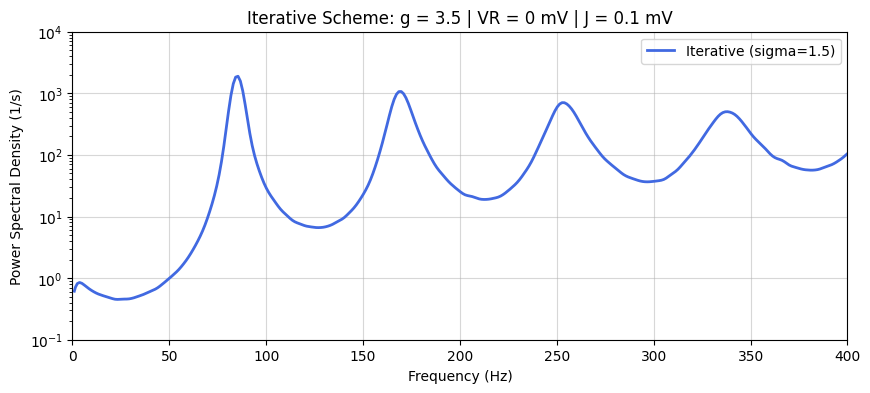

In [ ]:
# Smooth and plot the final PSD
sigma_val = 1.5


S_cur_smooth = gaussian_filter1d(S_cur, sigma=sigma_val)
f_cur_smooth = gaussian_filter1d(f_cur, sigma=sigma_val)

plt.figure(figsize=(10, 4))
plt.semilogy(f_cur_smooth, S_cur_smooth, color='royalblue', lw=2, label=f'Iterative (sigma={sigma_val})')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.title(f"Iterative Scheme: g = {g_val} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0.1, 10000])
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig(FIGURES_DIR / "G3.0_cell_20.png", dpi=150)
plt.show()

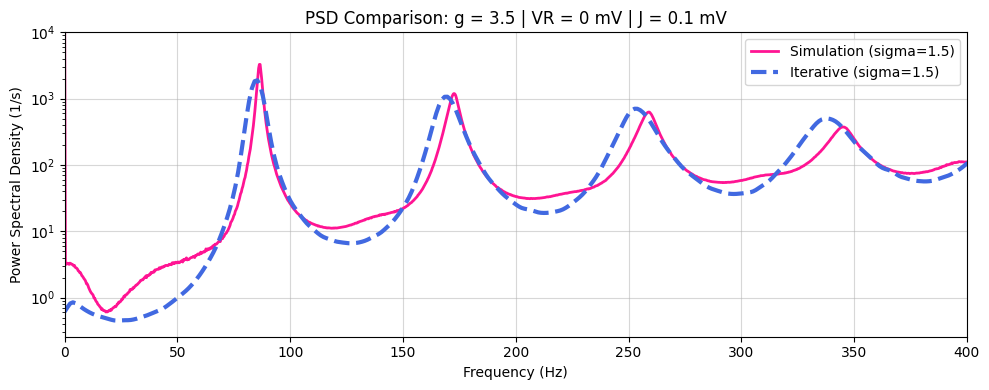

In [ ]:
# Initialize a single figure

T_sec = sim_time
f_brian = np.arange(len(Savg)) * (1.0 / T_sec)

plt.figure(figsize=(10, 4))

# 1. Plot the Brian2 Simulation Data
plt.semilogy(f_brian, Savg, color='deeppink', lw=2, label=f'Simulation (sigma={sigma_val})')

# 2. Plot the Iterative Scheme Data
plt.semilogy(f_cur, S_cur_smooth, color='royalblue', lw=3, ls= '--', label=f'Iterative (sigma={sigma_val})')

# Add formatting and labels
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power Spectral Density (1/s)')
plt.title(f"PSD Comparison: g = {g} | VR = {int(V_r/mV)} mV | J = {J/mV:.1f} mV")
plt.xlim([0, 400])
plt.ylim([0, 10000])
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
# Render the combined plot
plt.savefig(FIGURES_DIR / "G3.0_cell_22.png", dpi=150)
plt.show()

In [ ]:
print(f"Recurrent Network")
print(f" - Rate {average_firing_rate:.2f} Hz")
print(f" - CV: {mean_cv:.3f}")
print("-" * 30)
print(f"Iterative scheme: Generation {n_gen}")
print(f" - Rate = {nu_in:.2f} Hz")
print(f" - CV = {cv_gen_list[14]:.3f}")

Recurrent Network
 - Rate 85.82 Hz
 - CV: 0.070
------------------------------
Iterative scheme: Generation 15
 - Rate = 85.22 Hz
 - CV = 0.052


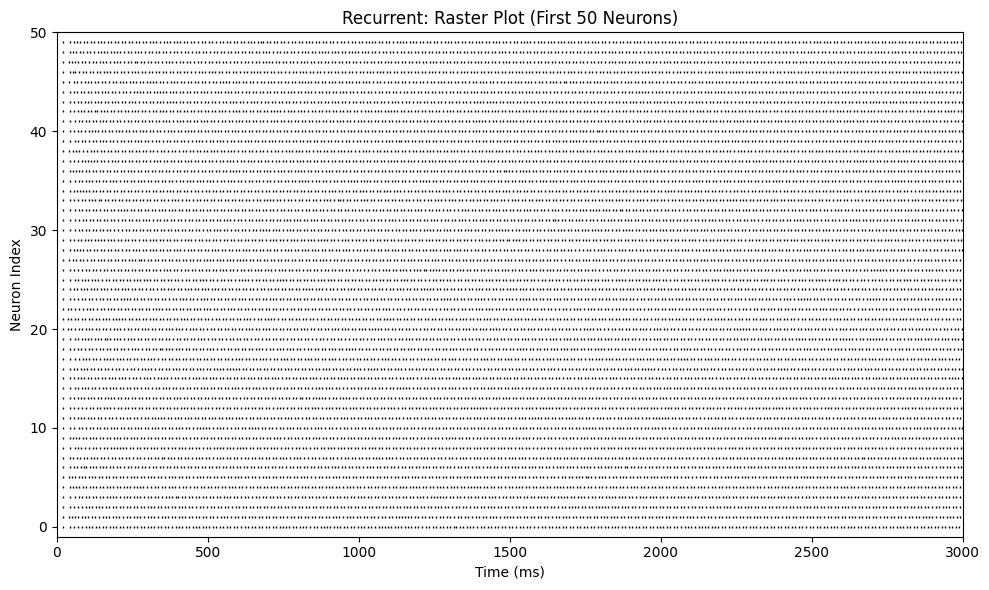

: 

In [ ]:
# Filter spikes for the first 50 neurons
neuron_mask = spike_mon.i <50

plt.figure(figsize=(10, 6))
plt.plot(spike_mon.t[neuron_mask] / ms, spike_mon.i[neuron_mask], '|', color='black', markersize=2)
plt.title('Recurrent: Raster Plot (First 50 Neurons)')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron Index')
plt.xlim(0, sim_time/ms)
plt.ylim(-1, 50)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "G3.5_cell_29.png", dpi=150)
plt.show()